Stage 0 — Project setup and system config
Stage 1 — Dataset preparation
Stage 2.1 — Feature construction
Stage 2.2 — Basis construction
Stage 3 — Model-selection candidate run
Stage 4 — Summary and selected model
Stage 5 — Model-selection visualizations
Stage 6 — Website-ready export

# Stage 0

In [1]:
from pathlib import Path
import sys
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

ARTIFACTS = PROJECT_ROOT / "artifacts"


print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC:", SRC)
print("ARTIFACTS:", ARTIFACTS)
#-------------------
# Change working directory to project root
os.chdir(PROJECT_ROOT)
print("CWD:", Path.cwd())

PROJECT_ROOT: .
SRC: ./src
ARTIFACTS: ./artifacts
CWD: .


In [2]:
SYSTEM_NAME = "sppcs"
PROFILE_NAME = "clumps"
TRIAL = 1

MODEL_SELECTION_MODE = "full_structure_selection"

TRAIN_SPLIT = "train"
TRAIN_FIT_SPLIT = "train_fit"
TEST_SPLIT = "test"
KDE_SPLIT = "kde"
VALIDATION_SPLIT = "validation"


TRAIN_DATASET_TEMPLATE = "dataset_train_trial_{trial:03d}"
TRAIN_FIT_DATASET_TEMPLATE = "dataset_train_fit_trial_{trial:03d}"

TRAIN_DATASET_NAME = TRAIN_DATASET_TEMPLATE.format(trial=TRIAL)
TRAIN_FIT_DATASET_NAME = TRAIN_FIT_DATASET_TEMPLATE.format(trial=TRIAL)

TEST_DATASET_NAME = "dataset_test"
KDE_DATASET_NAME = "dataset_kde"
VALIDATION_DATASET_NAME = "dataset_validation"

FIT_END_TIME = 0.5
PREDICTION_END_TIME = 2.0

In [3]:

SYSTEM_ARTIFACT_DIR = ARTIFACTS / SYSTEM_NAME

DATASET_DIR = ARTIFACTS / "datasets" / SYSTEM_NAME
FEATURE_DIR = ARTIFACTS / "features" / SYSTEM_NAME
BASIS_DIR = ARTIFACTS / "bases" / SYSTEM_NAME
FIT_DIR = ARTIFACTS / "fits" / SYSTEM_NAME
ROLLOUT_DIR = ARTIFACTS / "rollouts" / SYSTEM_NAME
EVALUATION_DIR = ARTIFACTS / "evaluations" / SYSTEM_NAME
DENSITY_DIR = ARTIFACTS / "densities"
MODEL_SELECTION_DIR = ARTIFACTS / "model_selection"
FIGURE_DIR = SYSTEM_ARTIFACT_DIR / "figures"

print("System:", SYSTEM_NAME)
print("Profile:", PROFILE_NAME)
print("Trial:", TRIAL)
print("Model-selection mode:", MODEL_SELECTION_MODE)

print("Train dataset:", TRAIN_DATASET_NAME)
print("Train-fit dataset:", TRAIN_FIT_DATASET_NAME)
print("Test dataset:", TEST_DATASET_NAME)
print("KDE dataset:", KDE_DATASET_NAME)
print("Validate dataset:", VALIDATION_DATASET_NAME)

print("FIT_END_TIME:", FIT_END_TIME)
print("PREDICTION_END_TIME:", PREDICTION_END_TIME)

System: sppcs
Profile: clumps
Trial: 1
Model-selection mode: full_structure_selection
Train dataset: dataset_train_trial_001
Train-fit dataset: dataset_train_fit_trial_001
Test dataset: dataset_test
KDE dataset: dataset_kde
Validate dataset: dataset_validation
FIT_END_TIME: 0.5
PREDICTION_END_TIME: 2.0


In [4]:
# ============================================================
# Stage 0.3 — Imports
# ============================================================

from ips_learning.data.dataset_repository import DatasetRepository

from ips_learning.features.feature_builder import FeatureBuilder
from ips_learning.features.feature_repository import FeatureRepository

from ips_learning.bases.specs import (
    BasisConfig,
    RadialBasisSpec,
    EnvironmentBasisSpec,
)
from ips_learning.bases.builders import BasisBuilder
from ips_learning.bases.repository import BasisRepository

from ips_learning.fitting.system_repository import NormalSystemRepository
from ips_learning.rollout.repository import RolloutRepository

from ips_learning.statistics.density import build_empirical_error_density
from ips_learning.statistics.density_repository import DensityRepository

from ips_learning.experiments.profile_registry import build_dataset_profile
from ips_learning.experiments.generate_dataset_collection import (
    generate_standard_dataset_collection,
)

from ips_learning.model_selection import (
    get_candidates,
    CandidateRunConfig,
    SelectionConfig,
    ModelSelectionRunner,
    ModelSelectionRepository,
    StaticModelSelectionWebsiteExporter,
    model_selection_rollout_fn,
    model_selection_evaluate_fn,
    model_selection_kernel_diagnostics_fn,
)
from ips_learning.model_selection.visualization import ModelSelectionVisualizer

In [5]:
# ============================================================
# Stage 0.4 — General helpers
# ============================================================

def ensure_dir(path: Path) -> Path:
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    return path


def path_exists(path: Path) -> bool:
    return Path(path).exists()


def load_json(path: Path) -> dict:
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(path)

    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(obj: dict, path: Path) -> None:
    path = Path(path)
    ensure_dir(path.parent)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True)


def first_existing_path(*paths: Path) -> Path | None:
    for path in paths:
        path = Path(path)
        if path.exists():
            return path
    return None


def pretty_path(path: Path) -> Path:
    path = Path(path).resolve()

    try:
        return path.relative_to(PROJECT_ROOT)
    except ValueError:
        return path

In [6]:
# ============================================================
# Stage 0.5 — Repository objects
# ============================================================

dataset_repo = DatasetRepository(root_dir=DATASET_DIR.parent)
feature_repo = FeatureRepository(root_dir=FEATURE_DIR.parent)
basis_repo = BasisRepository(root_dir=BASIS_DIR.parent)

fit_repo = NormalSystemRepository(root_dir=FIT_DIR.parent)
rollout_repo = RolloutRepository(root_dir=ROLLOUT_DIR.parent)
density_repo = DensityRepository(root=DENSITY_DIR)

ms_repo = ModelSelectionRepository(root_dir=MODEL_SELECTION_DIR)

runner = ModelSelectionRunner(
    fit_repo=fit_repo,
    ms_repo=ms_repo,
)

ms_viz = ModelSelectionVisualizer(repo=ms_repo)

website_exporter = StaticModelSelectionWebsiteExporter(
    artifact_root=ARTIFACTS,
    output_root=PROJECT_ROOT / "docs" / "assets" / "model_selection",
)

# Stage 1 — Benchmark dataset preparation

This stage generates or loads a fixed dataset collection for model selection.

All candidate models must use the same train-fit, validation, test, and KDE datasets. This keeps the comparison fair.

The workflow is:

- `train` is the full training trajectory collection.
- `train_fit` is the fitting window restricted to `[0, FIT_END_TIME]`.
- `validation` is used to select the model.
- `test` is used only for final reporting.
- `kde` is used for density/support diagnostics and kernel-weighted errors.

No candidate model is fitted in this stage.

In [7]:
# ============================================================
# Stage 1.1 — Generate or load benchmark dataset collection
# ============================================================

profile = build_dataset_profile(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
)

required_dataset_paths = [
    DATASET_DIR / TRAIN_SPLIT / TRAIN_DATASET_NAME / "trajectories.npz",
    DATASET_DIR / TRAIN_FIT_SPLIT / TRAIN_FIT_DATASET_NAME / "trajectories.npz",
    DATASET_DIR / TEST_SPLIT / TEST_DATASET_NAME / "trajectories.npz",
    DATASET_DIR / KDE_SPLIT / KDE_DATASET_NAME / "trajectories.npz",
     DATASET_DIR / VALIDATION_SPLIT / VALIDATION_DATASET_NAME / "trajectories.npz",
]

datasets_exist = all(path.exists() for path in required_dataset_paths)

if datasets_exist:
    print("Benchmark datasets already exist. Loading saved artifacts.")
else:
    print("Generating benchmark dataset collection.")
    generate_standard_dataset_collection(
        profile=profile,
        save_train_fit_split=True,
        fit_end_time=FIT_END_TIME,
    )

Benchmark datasets already exist. Loading saved artifacts.


In [8]:
# ============================================================
# Stage 1.2 — Load saved datasets
# ============================================================

train_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_SPLIT,
    dataset_name=TRAIN_DATASET_NAME,
)

train_fit_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TRAIN_FIT_SPLIT,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

validation_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=VALIDATION_SPLIT,
    dataset_name=VALIDATION_DATASET_NAME,
)

test_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=TEST_SPLIT,
    dataset_name=TEST_DATASET_NAME,
)

kde_dataset = dataset_repo.load(
    system_name=SYSTEM_NAME,
    split=KDE_SPLIT,
    dataset_name=KDE_DATASET_NAME,
)



print("Loaded datasets:")
print("train:", train_dataset.X.shape)
print("train_fit:", train_fit_dataset.X.shape)
print("validation:", validation_dataset.X.shape)
print("test:", test_dataset.X.shape)
print("kde:", kde_dataset.X.shape)

Loaded datasets:
train: (20, 201, 5, 2)
train_fit: (20, 51, 5, 2)
validation: (10, 201, 5, 2)
test: (20, 201, 5, 2)
kde: (2000, 51, 5, 2)


In [9]:
# ============================================================
# Stage 1.3 — Dataset sanity checks
# ============================================================

def check_second_order_dataset(name, dataset):
    assert dataset.X.ndim == 4, f"{name}.X must have shape (M, L, N, D)"
    assert dataset.V is not None, f"{name}.V is required for second-order model selection"
    assert dataset.LHS is not None, f"{name}.LHS is required"
    assert dataset.X.shape == dataset.V.shape == dataset.LHS.shape

    print(
        name,
        "X:", dataset.X.shape,
        "V:", dataset.V.shape,
        "LHS:", dataset.LHS.shape,
        "t:", dataset.t.shape,
    )


check_second_order_dataset("train", train_dataset)
check_second_order_dataset("train_fit", train_fit_dataset)
check_second_order_dataset("validation", validation_dataset)
check_second_order_dataset("test", test_dataset)
check_second_order_dataset("kde", kde_dataset)

assert train_fit_dataset.t[-1] <= FIT_END_TIME + 1e-12

train X: (20, 201, 5, 2) V: (20, 201, 5, 2) LHS: (20, 201, 5, 2) t: (201,)
train_fit X: (20, 51, 5, 2) V: (20, 51, 5, 2) LHS: (20, 51, 5, 2) t: (51,)
validation X: (10, 201, 5, 2) V: (10, 201, 5, 2) LHS: (10, 201, 5, 2) t: (201,)
test X: (20, 201, 5, 2) V: (20, 201, 5, 2) LHS: (20, 201, 5, 2) t: (201,)
kde X: (2000, 51, 5, 2) V: (2000, 51, 5, 2) LHS: (2000, 51, 5, 2) t: (51,)


# Stage 2 — Candidate-neutral feature and basis construction

This stage builds the shared feature and basis artifacts needed by all model-selection candidates.

The same feature artifact is used by:

- energy-only candidate,
- alignment-only candidate,
- full energy + alignment candidate.

Therefore the feature dataset must contain both position differences and velocity differences:

- `R_D` for energy interactions,
- `VR_D` for alignment interactions,
- `R` for radial kernel evaluation,
- `V` for the self/environment force `f(v)`,
- `LHS` for the acceleration target.

No candidate is fitted in this stage.

In [10]:
# ============================================================
# Stage 2.1 — Build or load train-fit features
# ============================================================

FEATURE_NAME = TRAIN_FIT_DATASET_NAME

feature_dir = (
    FEATURE_DIR
    / TRAIN_FIT_SPLIT
    / FEATURE_NAME
)

feature_path = feature_dir / "features.npz"

if feature_path.exists():
    print("Loading existing train-fit feature artifact.")
    train_fit_features = feature_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        feature_name=FEATURE_NAME,
    )
else:
    print("Building train-fit features.")
    train_fit_features = FeatureBuilder().build(train_fit_dataset)

    feature_repo.save(
        features=train_fit_features,
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        feature_name=FEATURE_NAME,
        overwrite=True,
    )

print("Feature artifact:", pretty_path(feature_path))
print("X:", train_fit_features.X.shape)
print("V:", None if train_fit_features.V is None else train_fit_features.V.shape)
print("LHS:", train_fit_features.LHS.shape)
print("R:", train_fit_features.R.shape)
print("R_D:", train_fit_features.R_D.shape)
print("VR_D:", None if train_fit_features.VR_D is None else train_fit_features.VR_D.shape)

Building train-fit features.
Feature artifact: artifacts/features/sppcs/train_fit/dataset_train_fit_trial_001/features.npz
X: (20, 51, 5, 2)
V: (20, 51, 5, 2)
LHS: (20, 51, 5, 2)
R: (20, 51, 5, 5, 1)
R_D: (20, 51, 5, 5, 2)
VR_D: (20, 51, 5, 5, 2)


In [11]:
# ============================================================
# Stage 2.2 — Feature sanity checks for model selection
# ============================================================

assert train_fit_features.metadata["system_order"] in (1, 2)

assert train_fit_features.X.ndim == 4
assert train_fit_features.V is not None
assert train_fit_features.LHS is not None

assert train_fit_features.R is not None
assert train_fit_features.R_D is not None
assert train_fit_features.VR_D is not None

assert train_fit_features.X.shape == train_fit_features.V.shape
assert train_fit_features.X.shape == train_fit_features.LHS.shape

print("Feature metadata system:", train_fit_features.metadata.get("system_name"))
print("Feature metadata order:", train_fit_features.metadata.get("system_order"))
print("Feature metadata interaction:", train_fit_features.metadata.get("interaction_type"))

Feature metadata system: sppcs
Feature metadata order: 2
Feature metadata interaction: energy_alignment


In [12]:
# ============================================================
# Stage 2.3 — Build or load model-selection basis bundle
# ============================================================

BASIS_NAME = f"{TRAIN_FIT_DATASET_NAME}_model_selection_basis"

basis_dir = (
    BASIS_DIR
    / TRAIN_FIT_SPLIT
    / BASIS_NAME
)

basis_path = basis_dir / "basis_bundle.pkl"

basis_config = BasisConfig(
    radial=RadialBasisSpec(family="bspline", degree=1, n_basis=10),
    energy=RadialBasisSpec(family="bspline", degree=1, n_basis=10),
    alignment=RadialBasisSpec(family="bspline", degree=1, n_basis=10),
    environment=EnvironmentBasisSpec(
        family="bspline",
        degree=1,
        n_basis_per_dim=10,
    ),
)

if basis_path.exists():
    print("Loading existing model-selection basis bundle.")
    basis_bundle = basis_repo.load(
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        basis_name=BASIS_NAME,
    )
else:
    print("Building model-selection basis bundle.")

    basis_bundle = BasisBuilder(basis_config).build(
        train_fit_features
    )

    # Full-model basis layout.
    # These are separate objects logically, even if they initially share
    # the same radial basis.
    if getattr(basis_bundle, "energy_basis", None) is None:
        basis_bundle.energy_basis = basis_bundle.radial_basis

    if getattr(basis_bundle, "alignment_basis", None) is None:
        basis_bundle.alignment_basis = basis_bundle.radial_basis

    basis_repo.save(
        basis_bundle=basis_bundle,
        system_name=SYSTEM_NAME,
        split=TRAIN_FIT_SPLIT,
        basis_name=BASIS_NAME,
        overwrite=True,
    )

print("Basis artifact:", pretty_path(basis_path))
print("Energy basis:", basis_bundle.energy_basis)
print("Alignment basis:", basis_bundle.alignment_basis)
print("Environment basis:", basis_bundle.environment_basis)

Building model-selection basis bundle.
Basis artifact: artifacts/bases/sppcs/train_fit/dataset_train_fit_trial_001_model_selection_basis/basis_bundle.pkl
Energy basis: RadialBasis(family='bspline', degree=1, n_basis=10, r_min=0.0, r_max=8.30010238666572, evaluator=<scipy.interpolate._bsplines.BSpline object at 0x116a18910>, knots=array([0.        , 0.        , 0.9222336 , 1.8444672 , 2.7667008 ,
       3.68893439, 4.61116799, 5.53340159, 6.45563519, 7.37786879,
       8.30010239, 8.30010239]))
Alignment basis: RadialBasis(family='bspline', degree=1, n_basis=10, r_min=0.0, r_max=8.30010238666572, evaluator=<scipy.interpolate._bsplines.BSpline object at 0x116a18b90>, knots=array([0.        , 0.        , 0.9222336 , 1.8444672 , 2.7667008 ,
       3.68893439, 4.61116799, 5.53340159, 6.45563519, 7.37786879,
       8.30010239, 8.30010239]))
Environment basis: EnvironmentBasis(family='bspline', degree=1, knots=[array([-2.82842712, -2.82842712, -2.19988776, -1.5713484 , -0.94280904,
       -0.

In [13]:
# ============================================================
# Stage 2.4 — Basis sanity checks
# ============================================================

energy_basis = getattr(basis_bundle, "energy_basis", None)
alignment_basis = getattr(basis_bundle, "alignment_basis", None)

assert energy_basis is not None
assert alignment_basis is not None
assert basis_bundle.environment_basis is not None

n_energy = energy_basis.n_basis
n_alignment = alignment_basis.n_basis

print("n_energy_basis:", n_energy)
print("n_alignment_basis:", n_alignment)
print("Energy/alignment bases are same object:", energy_basis is alignment_basis)

expected_interaction_blocks = {
    "second_order_energy": n_energy,
    "second_order_alignment": n_alignment,
    "second_order_energy_alignment": n_energy + n_alignment,
}

expected_interaction_blocks

n_energy_basis: 10
n_alignment_basis: 10
Energy/alignment bases are same object: False


{'second_order_energy': 10,
 'second_order_alignment': 10,
 'second_order_energy_alignment': 20}

# Stage 2.5 — Empirical train-fit density artifacts

This stage computes empirical density/support from the same `train_fit_dataset` used for fitting.

These densities are used only for visualization support/background:

- kernel plots use empirical pairwise-distance density,
- f plots use empirical environment-variable density.

They are saved once and loaded later. No candidate fitting happens here.

In [ ]:
# ============================================================
# Stage 2.5.1 — Build empirical train-fit density weights
# ============================================================

loc = basis_bundle.localization_metadata
system_order = train_fit_features.metadata["system_order"]

empirical_density = build_empirical_error_density(
    features=train_fit_features,
    localization_metadata=loc,
)

environment_variable = loc.get(
    "environment_variable",
    "position" if system_order == 1 else "velocity",
)


In [ ]:
# ============================================================
# Stage 2.5.2 — Distance density
# ============================================================

r_empirical_grid = empirical_density.r_grid
rho_R_empirical = empirical_density.kernel_weights


In [ ]:
# ============================================================
# Stage 2.5.3 — Environment density
# ============================================================

z1_grid = empirical_density.z1_grid
z2_grid = empirical_density.z2_grid

if z2_grid is None:
    train_density_grid = empirical_density.environment_weights
else:
    train_density_grid = empirical_density.environment_weights.reshape(
        len(z1_grid),
        len(z2_grid),
    )


# Stage 3 — Define model-selection candidates

This stage defines the candidate models that will compete on the same benchmark dataset.

No model is fitted in this stage.

In [17]:
# ============================================================
# Stage 3.1 — Candidate definitions
# ============================================================

candidates = get_candidates(MODEL_SELECTION_MODE)

candidate_table = pd.DataFrame(
    [
        {
            "candidate": c.name,
            "system_order": c.system_order,
            "interaction_type": c.interaction_type,
            "algorithm": c.algorithm,
            "description": c.description,
            "include_environment":c.include_environment,
            "complexity":c.complexity
        }
        for c in candidates
    ]
)

display(candidate_table)

,candidate,system_order,interaction_type,algorithm,description,include_environment,complexity
0,first_order_energy_only,1,energy,nonparametric_f,First-order energy-only model: dot_X = f_phi^E...,False,1
1,first_order_energy_f,1,energy,nonparametric_f,First-order energy model with environment forc...,True,2
2,second_order_energy_only,2,energy,nonparametric_f,Second-order energy-only model without environ...,False,3
3,second_order_alignment_only,2,alignment,nonparametric_f,Second-order alignment-only model without envi...,False,3
4,second_order_energy_f,2,energy,nonparametric_f,Second-order energy model with environment force.,True,4
5,second_order_alignment_f,2,alignment,nonparametric_f,Second-order alignment model with environment ...,True,4
6,second_order_energy_alignment_only,2,energy_alignment,nonparametric_f,Second-order energy-alignment model without en...,False,5
7,second_order_energy_alignment_f,2,energy_alignment,nonparametric_f,Second-order energy-alignment model with envir...,True,6


In [18]:
# ============================================================
# Stage 3.2 — Candidate sanity checks
# ============================================================

for candidate in candidates:
    candidate.validate()

assert len({c.name for c in candidates}) == len(candidates)

print("Number of candidates:", len(candidates))
print("Candidates:", [c.name for c in candidates])

Number of candidates: 8
Candidates: ['first_order_energy_only', 'first_order_energy_f', 'second_order_energy_only', 'second_order_alignment_only', 'second_order_energy_f', 'second_order_alignment_f', 'second_order_energy_alignment_only', 'second_order_energy_alignment_f']


In [19]:
train_fit_features.metadata["model_selection_mode"] = True
train_fit_features.metadata["generating_interaction_type"] = (
    train_fit_features.metadata.get("interaction_type")
)

# Stage 4 — Run candidate fits, rollouts, and evaluations

This stage runs the model-selection experiment.

For each candidate:

1. fit or load the candidate fit,
2. build the learned model,
3. run validation and test rollouts,
4. compute validation and test metrics,
5. save candidate artifacts.

The fit is not recomputed if it already exists and `overwrite_fit=False`.

In [20]:
# ============================================================
# Stage 4.1 — Runner configuration
# ============================================================

run_config = CandidateRunConfig(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    overwrite_fit=False,
    overwrite_metrics=True,
    ridge_lambda=1e-6,
    solver_method="lstsq",
    svd_tol=1e-12,
    parallel_jobs=1,
    primary_metric="E_traj_full",
         # Count the estimated Gaussian variance as one likelihood parameter
    include_noise_variance_parameter=True,
)


run_config.fit_end_time = FIT_END_TIME
run_config.prediction_end_time = PREDICTION_END_TIME

selection_config = SelectionConfig(
    primary_metric="E_traj_full",
    residual_metric="E_res",
    condition_metric="condition_number",
    relative_tie_tol=0.05,
    absolute_tie_tol=1e-3,
    max_condition_number=1e12,

    max_reconstruction_rel=0.25,
    max_residual_rel=0.25,

    reject_failed_rollouts=True,
    prefer_simpler_on_tie=True,
)

print(run_config)
print(selection_config)

CandidateRunConfig(system_name='sppcs', profile_name='clumps', dataset_name='dataset_train_fit_trial_001', overwrite_fit=False, overwrite_metrics=True, ridge_lambda=1e-06, solver_method='lstsq', svd_tol=1e-12, parallel_jobs=1, primary_metric='E_traj_full', include_noise_variance_parameter=True)
SelectionConfig(primary_metric='E_traj_full', residual_metric='E_res', condition_metric='condition_number', relative_tie_tol=0.05, absolute_tie_tol=0.001, max_condition_number=1000000000000.0, reject_failed_rollouts=True, prefer_simpler_on_tie=True, max_reconstruction_rel=0.25, max_residual_rel=0.25)


In [21]:
# ============================================================
# Stage 4.2 — Run model-selection experiment
# ============================================================

result = runner.run_select_and_save(
    candidates=candidates,
    train_dataset=train_dataset,
    # features_train_fit=train_fit_features,
    basis_bundle=basis_bundle,
    validation_dataset=validation_dataset,
    test_dataset=test_dataset,
    config=run_config,
    rollout_fn=model_selection_rollout_fn,
    evaluate_fn=model_selection_evaluate_fn,
    kernel_diagnostics_fn=model_selection_kernel_diagnostics_fn,
    selection_config=selection_config,
)

summary = result["summary"]
selected = result["selected"]

display(summary)
selected

,candidate,system_order,interaction_type,algorithm,include_environment,primary_metric,primary_value,E_traj_reconstruction,E_traj_reconstruction_std,E_traj_reconstruction_rel,...,rejection_reason,phi_E_norm,phi_A_norm,f_norm,rank,selected,aic_rank,aic_selected,bic_rank,bic_selected
0,second_order_energy_alignment_f,2,energy_alignment,nonparametric_f,True,E_traj_full,0.072231,0.002824,0.000652,0.000329,...,,0.456097,0.266221,1.540315,1,True,1.0,True,1.0,True
1,second_order_alignment_f,2,alignment,nonparametric_f,True,E_traj_full,0.354430,0.016163,0.005917,0.001897,...,,0.000000,0.306764,1.529049,2,False,2.0,False,2.0,False
2,second_order_energy_f,2,energy,nonparametric_f,True,E_traj_full,0.396505,0.017648,0.007537,0.002218,...,,0.563477,0.000000,1.703410,3,False,3.0,False,3.0,False
3,second_order_alignment_only,2,alignment,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,0.000000,1.440542,0.000000,4,False,NaN,False,NaN,False
4,first_order_energy_only,1,energy,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,1.386400,0.000000,0.000000,5,False,NaN,False,NaN,False
5,second_order_energy_alignment_only,2,energy_alignment,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,1.001786,1.546587,0.000000,6,False,NaN,False,NaN,False
6,first_order_energy_f,1,energy,nonparametric_f,True,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,0.563477,0.000000,7.081574,7,False,NaN,False,NaN,False
7,second_order_energy_only,2,energy,nonparametric_f,False,E_traj_full,2.176686,0.374131,0.099261,0.046624,...,large_residual,1.386400,0.000000,0.000000,8,False,4.0,False,4.0,False


{'candidate': 'second_order_energy_alignment_f',
 'system_order': 2,
 'interaction_type': 'energy_alignment',
 'algorithm': 'nonparametric_f',
 'include_environment': True,
 'primary_metric': 'E_traj_full',
 'primary_value': 0.0722314514639532,
 'E_traj_reconstruction': 0.002824093746430208,
 'E_traj_reconstruction_std': 0.0006516178011278992,
 'E_traj_reconstruction_rel': 0.0003288493848765571,
 'E_traj_prediction': 0.056496804723070324,
 'E_traj_prediction_std': 0.016458324596031717,
 'E_res': 0.0810014469144961,
 'E_res_rel': 0.024729677950815245,
 'E_traj_full': 0.0722314514639532,
 'E_traj_full_std': 0.03864320312212564,
 'condition_number': 1707858.274080959,
 'complexity': 6,
 'trajectory_reconstruction_rss': 0.010159843938784684,
 'trajectory_reconstruction_n_obs': 10200,
 'n_model_coefficients': 220,
 'n_likelihood_parameters': 221,
 'AIC': -111570.09692772,
 'BIC': -109972.2353248808,
 'accepted': True,
 'rejection_reason': '',
 'phi_E_norm': 0.45609737936199884,
 'phi_A_norm

In [22]:
# ------------------------------------------------------------
# Verify that the AIC/BIC fields were created
# ------------------------------------------------------------

required_information_criterion_columns = [
    "trajectory_reconstruction_rss",
    "trajectory_reconstruction_n_obs",
    "n_model_coefficients",
    "n_likelihood_parameters",
    "AIC",
    "BIC",
    "aic_rank",
    "bic_rank",
    "aic_selected",
    "bic_selected",
]

missing_columns = [
    column
    for column in required_information_criterion_columns
    if column not in summary.columns
]

if missing_columns:
    raise KeyError(
        "The model-selection summary is missing the following "
        f"AIC/BIC columns: {missing_columns}"
    )

# ------------------------------------------------------------
# Extract the candidates selected by each method
# ------------------------------------------------------------

aic_mask = (
    summary["aic_selected"]
    .astype(str)
    .str.lower()
    .eq("true")
)

bic_mask = (
    summary["bic_selected"]
    .astype(str)
    .str.lower()
    .eq("true")
)

aic_selected_rows = summary.loc[aic_mask]
bic_selected_rows = summary.loc[bic_mask]

if len(aic_selected_rows) != 1:
    raise RuntimeError(
        "Expected exactly one AIC-selected candidate, "
        f"but found {len(aic_selected_rows)}."
    )

if len(bic_selected_rows) != 1:
    raise RuntimeError(
        "Expected exactly one BIC-selected candidate, "
        f"but found {len(bic_selected_rows)}."
    )

aic_selected = aic_selected_rows.iloc[0].to_dict()
bic_selected = bic_selected_rows.iloc[0].to_dict()

# ------------------------------------------------------------
# Display a compact comparison
# ------------------------------------------------------------

comparison_columns = [
    "candidate",
    "trajectory_reconstruction_rss",
    "trajectory_reconstruction_n_obs",
    "n_model_coefficients",
    "n_likelihood_parameters",
    "AIC",
    "BIC",
    "rank",
    "aic_rank",
    "bic_rank",
    "selected",
    "aic_selected",
    "bic_selected",
]

display(summary[comparison_columns])

print("Proposed method:", selected["candidate"])
print("AIC:", aic_selected["candidate"])
print("BIC:", bic_selected["candidate"])

summary["trajectory_reconstruction_n_obs"].dropna().nunique()

,candidate,trajectory_reconstruction_rss,trajectory_reconstruction_n_obs,n_model_coefficients,n_likelihood_parameters,AIC,BIC,rank,aic_rank,bic_rank,selected,aic_selected,bic_selected
0,second_order_energy_alignment_f,0.010160,10200.0,220,221.0,-111570.096928,-109972.235325,1,1.0,1.0,True,True,True
1,second_order_alignment_f,0.338202,10200.0,210,211.0,-75837.059961,-74311.499788,2,2.0,2.0,False,False,False
2,second_order_energy_f,0.462209,10200.0,210,211.0,-72650.843996,-71125.283823,3,3.0,3.0,False,False,False
3,second_order_alignment_only,NaN,NaN,10,NaN,NaN,NaN,4,NaN,NaN,False,False,False
4,first_order_energy_only,NaN,NaN,10,NaN,NaN,NaN,5,NaN,NaN,False,False,False
5,second_order_energy_alignment_only,NaN,NaN,20,NaN,NaN,NaN,6,NaN,NaN,False,False,False
6,first_order_energy_f,NaN,NaN,210,NaN,NaN,NaN,7,NaN,NaN,False,False,False
7,second_order_energy_only,204.227812,10200.0,10,11.0,-10922.904347,-10843.372774,8,4.0,4.0,False,False,False


Proposed method: second_order_energy_alignment_f
AIC: second_order_energy_alignment_f
BIC: second_order_energy_alignment_f


1

In [23]:
# ============================================================
# Stage 4.3 — Inspect candidate artifact references
# ============================================================

for run_result in result["run_results"]:
    print("\nCandidate:", run_result.candidate_name)
    print("Fit path:", pretty_path(run_result.fit_path))
    print("Validation metrics:", run_result.validation_metrics)
    print("Test metrics:", run_result.test_metrics)
    print("References:")
    for key, value in run_result.artifact_references.items():
        print("  ", key, "->", value)


Candidate: first_order_energy_only
Fit path: artifacts/fits/sppcs/clumps/nonparametric_f/dataset_train_fit_trial_001__first_order_energy_only/fit_result.pkl
Validation metrics: {'status': 'failed_rollout', 'failed': True, 'candidate': 'first_order_energy_only', 'split': 'validation', 'error': 'TypeError("\'NoneType\' object is not subscriptable")', 'n_model_coefficients': 10, 'information_criteria_status': 'not_available', 'n_variance_parameters': 1, 'n_likelihood_parameters': None, 'sigma2_mle': None, 'log_likelihood': None, 'negative_two_log_likelihood': None, 'AIC': None, 'BIC': None, 'condition_number': 2114.0340732483614}
Test metrics: None
References:
   fit_result -> ./artifacts/fits/sppcs/clumps/nonparametric_f/dataset_train_fit_trial_001__first_order_energy_only/fit_result.pkl
   kernel_diagnostics -> ./artifacts/model_selection/sppcs/clumps/dataset_train_fit_trial_001/candidates/first_order_energy_only/kernel_diagnostics.npz

Candidate: first_order_energy_f
Fit path: artifac

In [24]:
# ============================================================
# Inspect saved candidate metrics
# ============================================================

saved_metric_rows = []

for candidate in candidates:
    try:
        metrics = ms_repo.load_candidate_metrics(
            system_name=SYSTEM_NAME,
            profile_name=PROFILE_NAME,
            dataset_name=TRAIN_FIT_DATASET_NAME,
            candidate_name=candidate.name,
            split="validation",
        )

        saved_metric_rows.append(
            {
                "candidate": candidate.name,
                "status": metrics.get("status"),
                "failed": metrics.get("failed"),
                "E_res": metrics.get("E_res"),
                "E_res_rel": metrics.get("E_res_rel"),
                "E_recon_rel": metrics.get(
                    "E_traj_reconstruction_rel"
                ),
                "E_full_validation": metrics.get(
                    "E_traj_full"
                ),
                "RSS": metrics.get(
                    "trajectory_reconstruction_rss"
                ),
                "k": metrics.get(
                    "n_likelihood_parameters"
                ),
                "AIC": metrics.get("AIC"),
                "BIC": metrics.get("BIC"),
                "error": metrics.get("error"),
            }
        )

    except FileNotFoundError as exc:
        saved_metric_rows.append(
            {
                "candidate": candidate.name,
                "status": "file_missing",
                "error": repr(exc),
            }
        )

saved_metrics_df = pd.DataFrame(saved_metric_rows)

display(saved_metrics_df)

,candidate,status,failed,E_res,E_res_rel,E_recon_rel,E_full_validation,RSS,k,AIC,BIC,error
0,first_order_energy_only,failed_rollout,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"TypeError(""'NoneType' object is not subscripta..."
1,first_order_energy_f,failed_rollout,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"TypeError(""'NoneType' object is not subscripta..."
2,second_order_energy_only,ok,False,3.169949,0.967783,0.046624,2.176686,204.227812,11.0,-10922.904347,-10843.372774,NaN
3,second_order_alignment_only,failed_rollout,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,RuntimeError('Rollout failed for candidate=sec...
4,second_order_energy_f,ok,False,0.258922,0.079049,0.002218,0.396505,0.462209,211.0,-72650.843996,-71125.283823,NaN
5,second_order_alignment_f,ok,False,0.200624,0.061250,0.001897,0.354430,0.338202,211.0,-75837.059961,-74311.499788,NaN
6,second_order_energy_alignment_only,failed_rollout,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,RuntimeError('Rollout failed for candidate=sec...
7,second_order_energy_alignment_f,ok,False,0.081001,0.024730,0.000329,0.072231,0.010160,221.0,-111570.096928,-109972.235325,NaN


# Stage 5 — Load saved model-selection outputs

This stage reloads the saved summary table and selected model from artifacts.

This confirms that later plotting and reporting can happen without rerunning fits or rollouts.

In [25]:
# ============================================================
# Stage 5.1 — Reload summary and selected model
# ============================================================

summary = ms_repo.load_summary_table(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

selected = ms_repo.load_selected_model(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

display(summary)
selected

,candidate,system_order,interaction_type,algorithm,include_environment,primary_metric,primary_value,E_traj_reconstruction,E_traj_reconstruction_std,E_traj_reconstruction_rel,...,rejection_reason,phi_E_norm,phi_A_norm,f_norm,rank,selected,aic_rank,aic_selected,bic_rank,bic_selected
0,second_order_energy_alignment_f,2,energy_alignment,nonparametric_f,True,E_traj_full,0.072231,0.002824,0.000652,0.000329,...,NaN,0.456097,0.266221,1.540315,1,True,1.0,True,1.0,True
1,second_order_alignment_f,2,alignment,nonparametric_f,True,E_traj_full,0.354430,0.016163,0.005917,0.001897,...,NaN,0.000000,0.306764,1.529049,2,False,2.0,False,2.0,False
2,second_order_energy_f,2,energy,nonparametric_f,True,E_traj_full,0.396505,0.017648,0.007537,0.002218,...,NaN,0.563477,0.000000,1.703410,3,False,3.0,False,3.0,False
3,second_order_alignment_only,2,alignment,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,0.000000,1.440542,0.000000,4,False,NaN,False,NaN,False
4,first_order_energy_only,1,energy,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,1.386400,0.000000,0.000000,5,False,NaN,False,NaN,False
5,second_order_energy_alignment_only,2,energy_alignment,nonparametric_f,False,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,1.001786,1.546587,0.000000,6,False,NaN,False,NaN,False
6,first_order_energy_f,1,energy,nonparametric_f,True,E_traj_full,inf,NaN,NaN,NaN,...,failed_rollout,0.563477,0.000000,7.081574,7,False,NaN,False,NaN,False
7,second_order_energy_only,2,energy,nonparametric_f,False,E_traj_full,2.176686,0.374131,0.099261,0.046624,...,large_residual,1.386400,0.000000,0.000000,8,False,4.0,False,4.0,False


{'candidate': 'second_order_energy_alignment_f',
 'system_order': 2,
 'interaction_type': 'energy_alignment',
 'algorithm': 'nonparametric_f',
 'include_environment': True,
 'primary_metric': 'E_traj_full',
 'primary_value': 0.0722314514639532,
 'E_traj_reconstruction': 0.002824093746430208,
 'E_traj_reconstruction_std': 0.0006516178011278992,
 'E_traj_reconstruction_rel': 0.0003288493848765571,
 'E_traj_prediction': 0.056496804723070324,
 'E_traj_prediction_std': 0.016458324596031717,
 'E_res': 0.0810014469144961,
 'E_res_rel': 0.024729677950815245,
 'E_traj_full': 0.0722314514639532,
 'E_traj_full_std': 0.03864320312212564,
 'condition_number': 1707858.274080959,
 'complexity': 6,
 'trajectory_reconstruction_rss': 0.010159843938784684,
 'trajectory_reconstruction_n_obs': 10200,
 'n_model_coefficients': 220,
 'n_likelihood_parameters': 221,
 'AIC': -111570.09692772,
 'BIC': -109972.2353248808,
 'accepted': True,
 'rejection_reason': '',
 'phi_E_norm': 0.45609737936199884,
 'phi_A_norm

In [26]:
# ============================================================
# Stage 5.2 — Selection checks
# ============================================================

assert selected["selection_status"] == "selected"
assert "candidate" in selected
assert np.isfinite(summary["primary_value"].astype(float)).any()

SELECTED_CANDIDATE = selected["candidate"]

print("Selected candidate:", SELECTED_CANDIDATE)
print("Selection metric:", selected["primary_metric"])
print("Selected value:", selected["primary_value"])

Selected candidate: second_order_energy_alignment_f
Selection metric: E_traj_full
Selected value: 0.0722314514639532


# Stage 6 — Candidate diagnostics

This stage inspects candidate-level metrics and kernel norms.

These diagnostics help distinguish active and inactive mechanisms:

- large `phi_E_norm` suggests active energy interaction,
- large `phi_A_norm` suggests active alignment interaction,
- near-zero norms suggest inactive or unsupported mechanisms.

In [27]:
# ============================================================
# Stage 6.1 — Compact model-selection table
# ============================================================

summary_cols = [
    "rank",
    "selected",
    "candidate",
    "interaction_type",
    "primary_value",
    "E_res",
    "phi_E_norm",
    "phi_A_norm",
    "theta_phi_E_norm",
    "theta_phi_A_norm",
    "theta_f_norm",
    "f_norm",
    "accepted",
    "rejection_reason",
]

summary_compact = summary[
    [col for col in summary_cols if col in summary.columns]
].copy()

display(summary_compact)

,rank,selected,candidate,interaction_type,primary_value,E_res,phi_E_norm,phi_A_norm,f_norm,accepted,rejection_reason
0,1,True,second_order_energy_alignment_f,energy_alignment,0.072231,0.081001,0.456097,0.266221,1.540315,True,NaN
1,2,False,second_order_alignment_f,alignment,0.354430,0.200624,0.000000,0.306764,1.529049,True,NaN
2,3,False,second_order_energy_f,energy,0.396505,0.258922,0.563477,0.000000,1.703410,True,NaN
3,4,False,second_order_alignment_only,alignment,inf,inf,0.000000,1.440542,0.000000,False,failed_rollout
4,5,False,first_order_energy_only,energy,inf,inf,1.386400,0.000000,0.000000,False,failed_rollout
5,6,False,second_order_energy_alignment_only,energy_alignment,inf,inf,1.001786,1.546587,0.000000,False,failed_rollout
6,7,False,first_order_energy_f,energy,inf,inf,0.563477,0.000000,7.081574,False,failed_rollout
7,8,False,second_order_energy_only,energy,2.176686,3.169949,1.386400,0.000000,0.000000,False,large_residual


In [28]:
# ============================================================
# Stage 6.2 — Load full-model kernel diagnostics
# ============================================================

FULL_CANDIDATE = "second_order_energy_alignment_f"

full_kernel_diag = ms_repo.load_kernel_diagnostics(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    candidate_name=FULL_CANDIDATE,
)

print("Available kernel diagnostic keys:")
print(sorted(full_kernel_diag.keys()))

print("phi_E_norm:", float(full_kernel_diag["phi_E_norm"]))
print("phi_A_norm:", float(full_kernel_diag["phi_A_norm"]))
print("f_norm:", float(full_kernel_diag["f_norm"]))

Available kernel diagnostic keys:
['condition_number', 'f_norm', 'phi_A', 'phi_A_norm', 'phi_E', 'phi_E_norm', 'r_grid']
phi_E_norm: 0.45609737936199884
phi_A_norm: 0.26622067661730786
f_norm: 1.5403151714563161


# Stage 7 — Model-selection visualizations from saved artifacts

This stage creates plots only from saved artifacts.

It does not rerun fitting or rollout.

In [29]:
# ============================================================
# Stage 7.1 — True system for true-kernel overlays
# ============================================================

profile = build_dataset_profile(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
)

true_system = profile.system_factory(
    N=profile.common_config["N"],
    D=profile.common_config["D"],
    **profile.common_config.get("system_params", {}),
)

true_energy_kernel = getattr(true_system, "energy_kernel", None)
true_alignment_kernel = getattr(true_system, "alignment_kernel", None)

print("Has true energy kernel:", true_energy_kernel is not None)
print("Has true alignment kernel:", true_alignment_kernel is not None)

Has true energy kernel: True
Has true alignment kernel: True


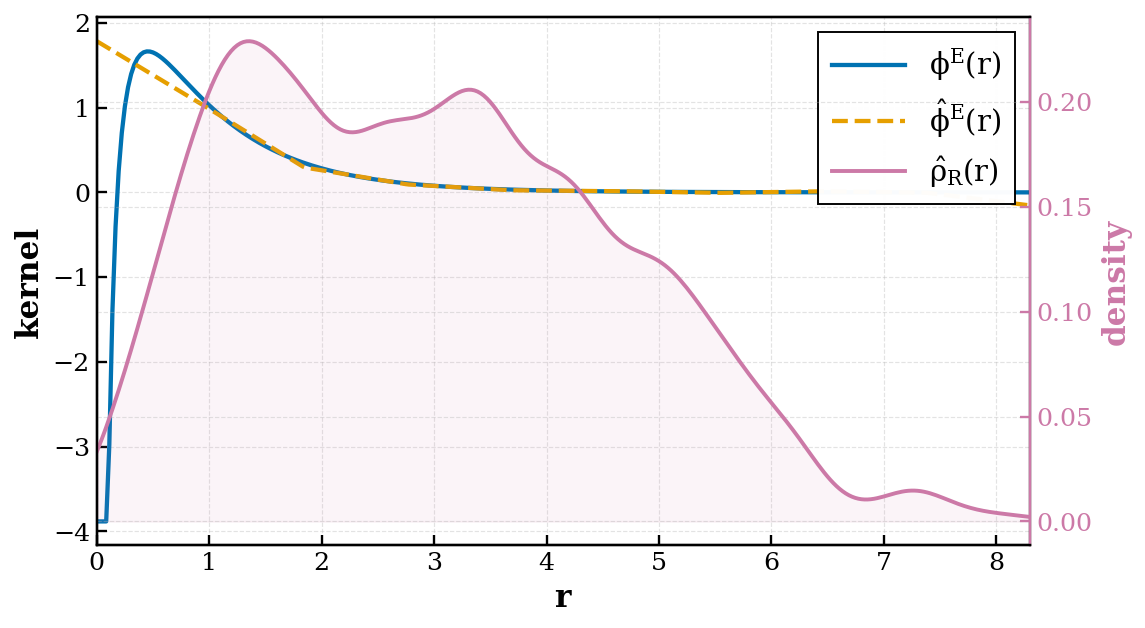

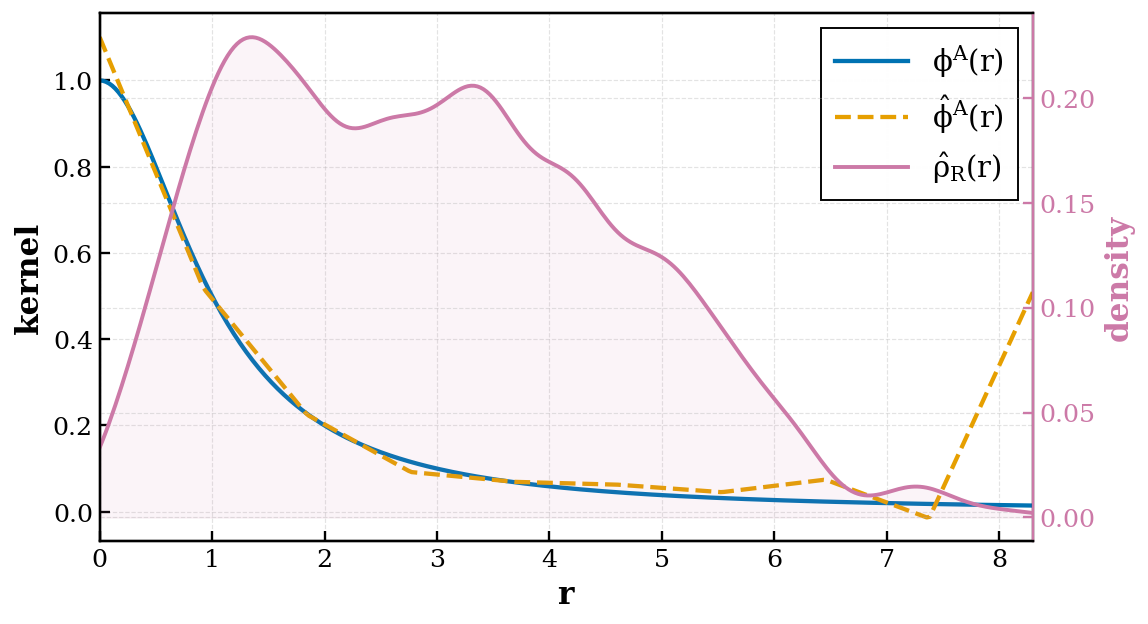

In [30]:
# ============================================================
# Stage 7.2 — Plot full-model energy and alignment kernels
# ============================================================

fig_E, fig_A = ms_viz.plot_energy_alignment_kernels(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    candidate_name=FULL_CANDIDATE,
    true_energy_kernel=true_energy_kernel,
    true_alignment_kernel=true_alignment_kernel,
    energy_density=rho_R_empirical,
    alignment_density=rho_R_empirical,
)

plt.show()

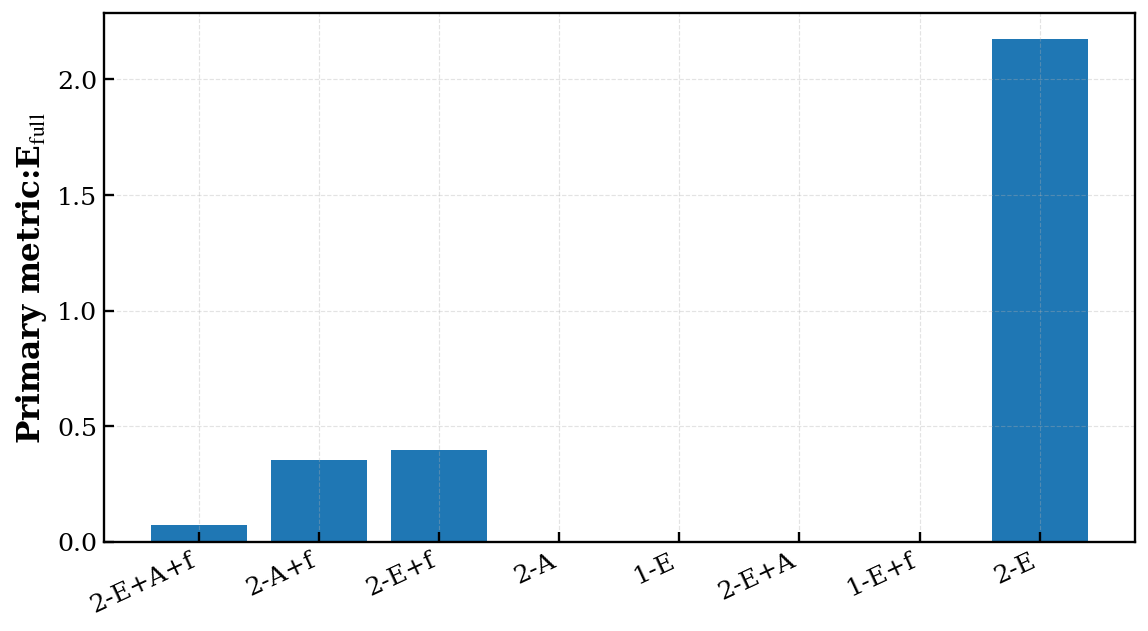

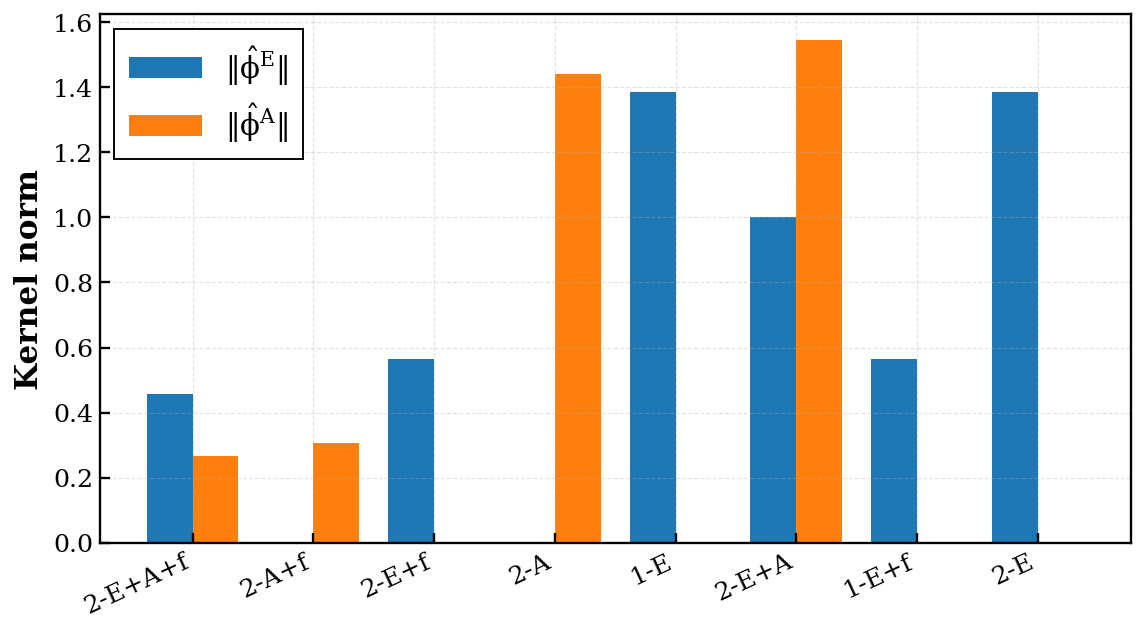

In [31]:
# ============================================================
# Stage 7.3 — Plot candidate score summary and kernel norms
# ============================================================
candidate_labels = {
    "first_order_energy_only": "1-E",
    "first_order_energy_f": "1-E+f",

    "second_order_energy_only": "2-E",
    "second_order_alignment_only": "2-A",

    "second_order_energy_f": "2-E+f",
    "second_order_alignment_f": "2-A+f",

    "second_order_energy_alignment_only": "2-E+A",
    "second_order_energy_alignment_f": "2-E+A+f",
}

fig_scores = ms_viz.plot_selection_summary(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    metric="primary_value",
    candidate_labels=candidate_labels
)

fig_norms = ms_viz.plot_candidate_kernel_norms(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    candidate_labels=candidate_labels
)

plt.show()

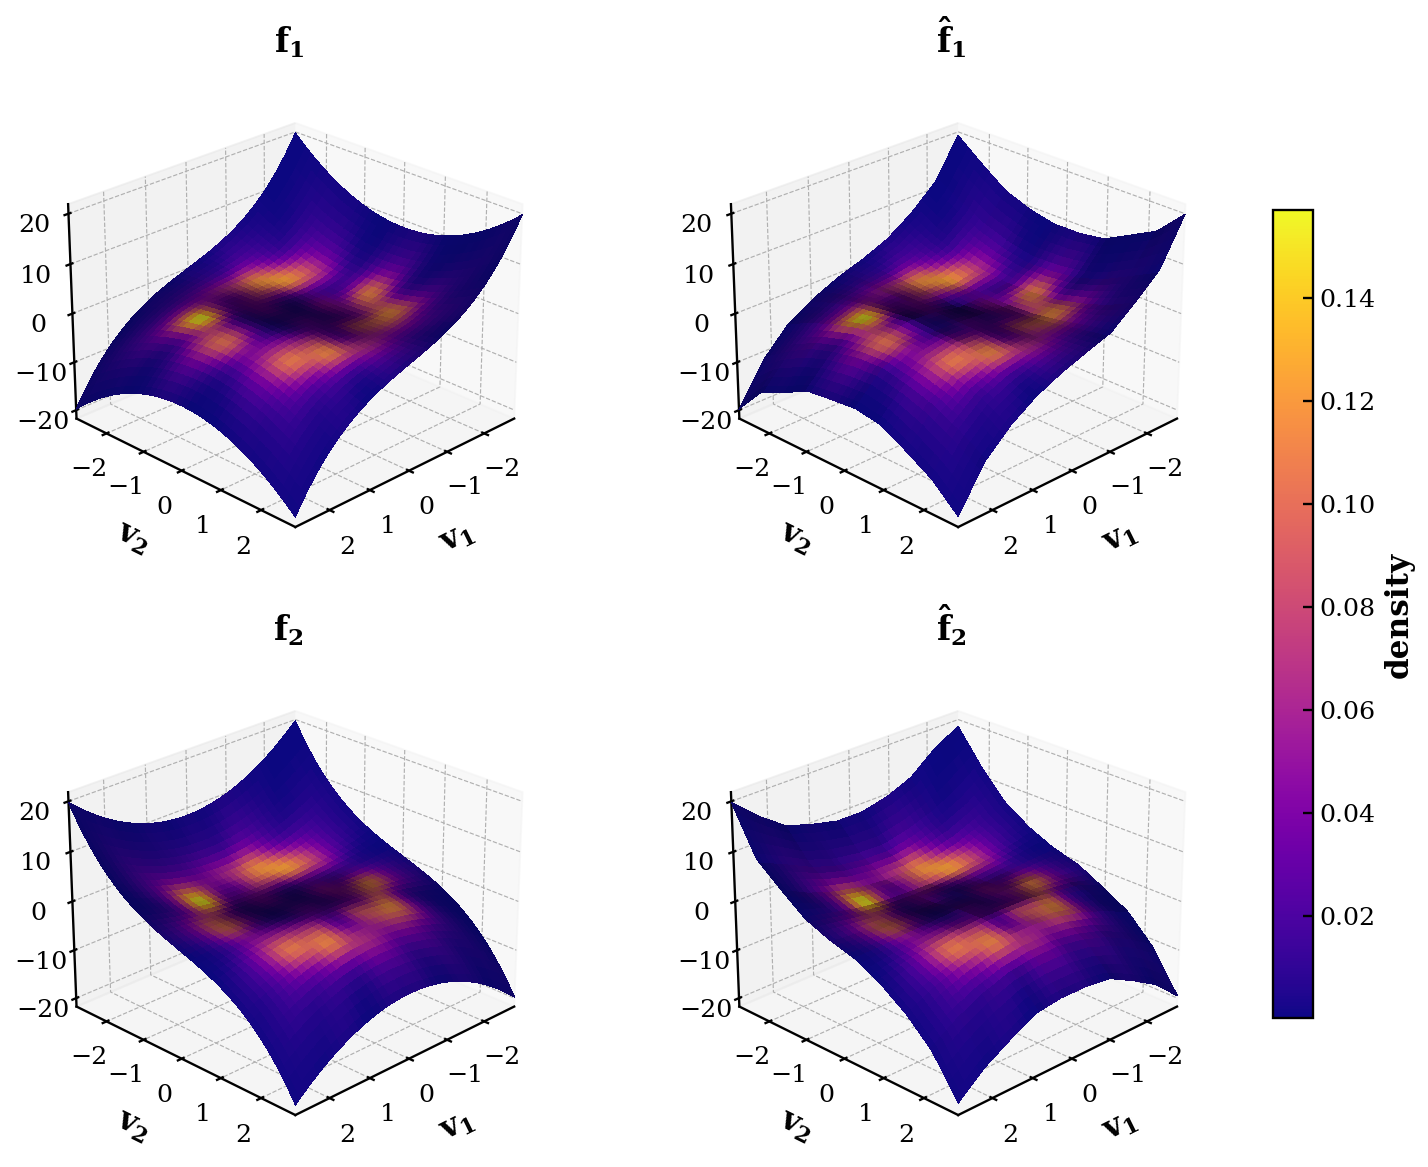

In [32]:
# ============================================================
# Stage 7.3 — Plot f
# ============================================================
fig_f = ms_viz.plot_candidate_environment(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    candidate_name=FULL_CANDIDATE,
    fit_repo=fit_repo,
    z1_grid=z1_grid,
    z2_grid=z2_grid,
    reference_density=train_density_grid,
    true_env=true_system.f_env,
    environment_variable="v",
    zlim_mode="joint",
)

plt.show()


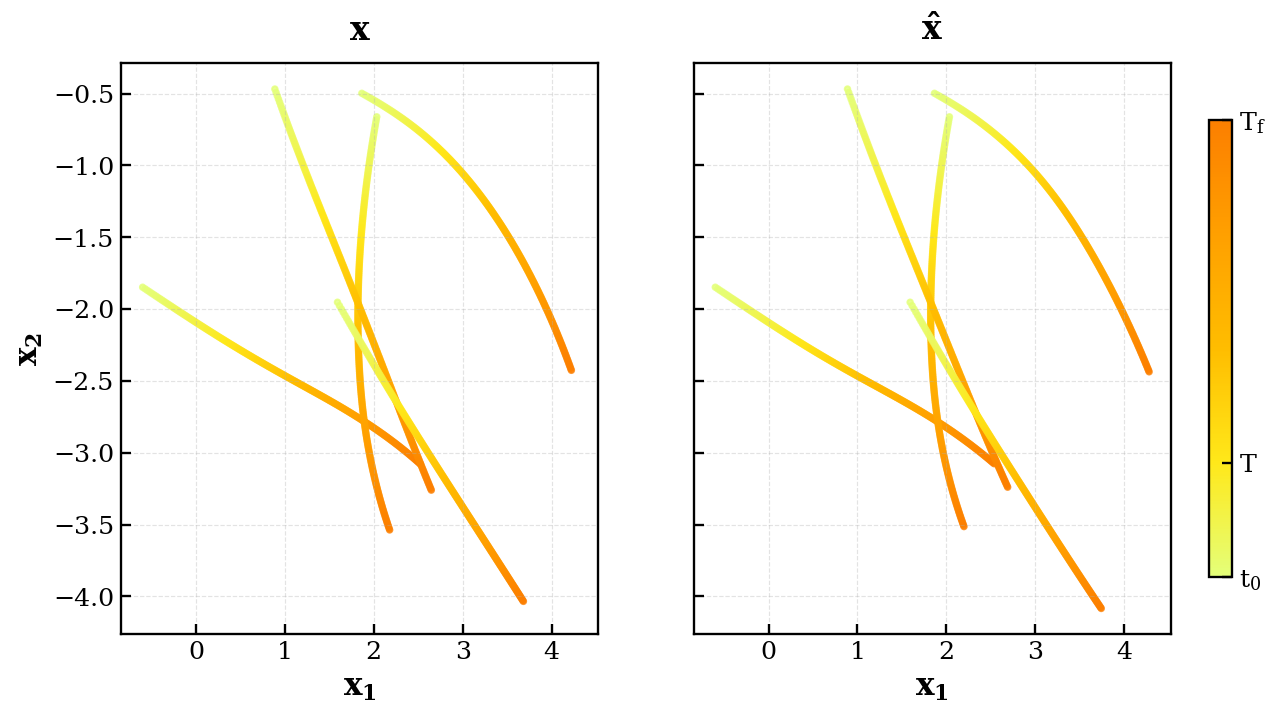

In [33]:
# ============================================================
# Stage 7.4 — Plot selected candidate test rollout
# ============================================================

selected_refs = ms_repo.load_candidate_references(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
    candidate_name=SELECTED_CANDIDATE,
)

test_rollout_path = selected_refs["test_rollout"]

fig_rollout = ms_viz.plot_rollout_by_order(
    rollout_path=test_rollout_path,
    system_order=selected.get("system_order", 2),
    trajectory_index=0,
    train_fit_end_pt=FIT_END_TIME,
)

# Stage 8 — Save figures

This stage saves all model-selection figures under the model-selection artifact directory.

In [34]:
# # ============================================================
# # Stage 8.1 — Save model-selection figures
# # ============================================================

# figures_dir = ms_repo.figures_dir(
#     system_name=SYSTEM_NAME,
#     profile_name=PROFILE_NAME,
#     dataset_name=TRAIN_FIT_DATASET_NAME,
# )

# kernel_fig_dir = ensure_dir(figures_dir / "kernels")
# score_fig_dir = ensure_dir(figures_dir / "scores")
# rollout_fig_dir = ensure_dir(figures_dir / "rollouts")
# env_fig_dir = ensure_dir(figures_dir / "environment")

# fig_E.savefig(
#     kernel_fig_dir / "full_model_energy_kernel.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig_A.savefig(
#     kernel_fig_dir / "full_model_alignment_kernel.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig_scores.savefig(
#     score_fig_dir / "selection_summary.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig_norms.savefig(
#     score_fig_dir / "kernel_norms.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig_rollout.savefig(
#     rollout_fig_dir / f"{SELECTED_CANDIDATE}_validation_rollout.png",
#     dpi=300,
#     bbox_inches="tight",
# )

# fig_f.savefig(
#     env_fig_dir / f"{SELECTED_CANDIDATE}_f.png",
#     dpi=300,
#     bbox_inches="tight",
# )
# print("Saved figures to:", pretty_path(figures_dir))
figures_dir = ms_repo.figures_dir(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

kernel_fig_dir = ensure_dir(figures_dir / "kernels")
score_fig_dir = ensure_dir(figures_dir / "scores")
rollout_fig_dir = ensure_dir(figures_dir / "rollouts")
env_fig_dir = ensure_dir(figures_dir / "environment")

def save_fig(fig, dir, name):
    fig.savefig(
        dir / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        dir / f"{name}.pdf",
        bbox_inches="tight",
    )

    
save_fig(fig_E, kernel_fig_dir, "full_model_energy_kernel")
save_fig(fig_A, kernel_fig_dir, "full_model_alignment_kernel")
save_fig(fig_scores, score_fig_dir, "selection_summary")
save_fig(fig_norms, score_fig_dir, "kernel_norms")
save_fig(fig_rollout, rollout_fig_dir, f"{SELECTED_CANDIDATE}_test_rollout")
save_fig(fig_f, env_fig_dir, f"{FULL_CANDIDATE}_f")

print("Saved figures to:", pretty_path(figures_dir))

Saved figures to: artifacts/model_selection/sppcs/clumps/dataset_train_fit_trial_001/figures


# Stage 9 — Website-ready export

This stage exports only website-safe artifacts:

- summary table,
- selected model JSON,
- figures,
- manifest JSON.

It does not export large fit or rollout files.

In [35]:
# ============================================================
# Stage 9.1 — Export website-ready results
# ============================================================

out_dir = website_exporter.export_system(
    system_name=SYSTEM_NAME,
    profile_name=PROFILE_NAME,
    dataset_name=TRAIN_FIT_DATASET_NAME,
)

print("Website export:", pretty_path(out_dir))

assert (out_dir / "manifest.json").exists()
assert (out_dir / "selected_model.json").exists()
assert (out_dir / "summary_table.csv").exists()

Website export: docs/assets/model_selection/sppcs


In [36]:
# ============================================================
# Stage 9.2 — Inspect manifest
# ============================================================

manifest = load_json(out_dir / "manifest.json")
manifest.keys()


dict_keys(['system_name', 'profile_name', 'dataset_name', 'selected_model', 'summary_table', 'repeated_trial_tables', 'summary_records', 'repeated_trial_records', 'figures'])